# Stage 15 — Tezin yöntemini anlatma ve bulguları görselleştirme (v1)

**Amaç:** Stage 13–14'te dondurulmuş bağımsız final testin sonuçlarını okuyarak tez giriş/yöntem/bulgularında kullanılacak **Türkçe, kaynak dosyaya bağlı grafik ve şemalar** üretmek. Bu aşama **model eğitmez, inference yapmaz, örnek seçmez, eşik optimize etmez ve önceki stage dosyalarının hiçbirini değiştirmez**.

- `Şekil 01–02`: kavramsal anlatım ve deney akışı; **veri grafiği değil**, bu şekilde altyazılandırın.
- `Şekil 03–09`: dondurulmuş final-test verisinden oluşturulan betimleyici grafikler; her modelin 250 bağımsız sorusu üzerinden hesaplanmıştır.
- Çıktı klasörü: `results/stage15/validated_v012_final250_v1/figures/` (PNG 240 dpi + düzenlenebilir SVG); `stage15_visualization_manifest_v1.json` yalnızca yeni Stage 15 çıktılarını belgeler.

**Girişte kullanım:** İlk 4–5 sayfalık giriş bölümüne esas olarak Şekil 01 veya 02'yi koyun. Test metriklerini gösteren Şekil 03–09'u deneysel bulgular/tartışma bölümüne ayırın; kısa tez önerisi yazıyorsanız bunları açıkça *ön bulgular* olarak konumlandırın. Çok sayıda görselle giriş bölümünü doldurmayın.

**Sınırlılık:** Final test, zorluk kotaları önceden belgelenerek gevşetilmiş 8 easy, 209 medium, 33 hard sorudan oluşuyor. Buradaki görseller yalnız bu üç model, bu soru kümesi ve bu dondurulmuş deney için geçerlidir.

## 0 — Drive bağlantısı ve paketler

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%pip -q install "pandas>=2,<3" "numpy>=1.26,<3" "matplotlib>=3.8,<4" "pyarrow>=15,<25"

Mounted at /content/drive


## 1 — Salt-okunur kaynaklar ve SHA-256 denetimi

Aşağıdaki değerler **Stage 13–14'ün daha önce raporlanmış SHA değerleriyle** sabitlenmiştir. Herhangi biri uyuşmazsa grafikleri üretmeyin; eski stage çıktılarını silip tekrar çalıştırmayın.

In [2]:
from pathlib import Path
import json, hashlib, math, os
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display

ROOT=Path('/content/drive/MyDrive/LLM_Confidence_Thesis')
VER='validated_v012_final250_v1'
S13=ROOT/'results'/'stage13'/VER
S14=ROOT/'results'/'stage14'/VER
OUT=ROOT/'results'/'stage15'/VER
FIG=OUT/'figures'
METRICS=S14/'final_test_metrics_v1.csv'
SELECTIVE=S14/'final_test_selective_v1.csv'
BOOT=S14/'final_test_paired_bootstrap_v1.csv'
EVAL_MAN=S14/'stage14_evaluation_manifest_v1.json'
PRED=S14/'final_test_predictions_v1.parquet'
PRED_MAN=S14/'stage14_predictions_manifest_v1.json'
CORE=ROOT/'features'/'assembled'/VER/'core_model_matrix_v1.parquet'
SPLIT=S13/'candidate_split_registry_v1.json'
S13_MAN=S13/'stage13_final_test_manifest_v1.json'
AMEND=S13/'stage12_v2_difficulty_amendment_v1.json'

EXPECTED={
    METRICS:'3f582f58327d9a84f7da6aea3427ce5b149b2d90a4b31a1a2e89b68afb8800b7',
    SELECTIVE:'bc86e1bf68f03c91d184e39c0517b704fdb7b1960900e98c29cb2f34081a3d71',
    BOOT:'6094181c73577dd938a1ecad9499cf1a9fa4a2d9efd6e49c774fefc5b6dac116',
    EVAL_MAN:'a68baf340eda3092864cb17ec027675ac8f90e67000edb6cd7e9791d26456fac',
    PRED:'6b00973b5b867994f0bc26805fea0893021b3f724d97e4b84e4124c7d17ab8fb',
    CORE:'9003bcc9c4e11fa1c4d68259fad5420e86c7919caa6a5a04670f5215320209f0',
    S13_MAN:'5742d8c4df190373358a9e0533e55b57ea334ab20d87606cd3a0d320b910fc94',
}
def sha(path):
    path=Path(path)
    assert path.is_file(), f'Kaynak dosya eksik: {path}'
    h=hashlib.sha256()
    with path.open('rb') as f:
        for part in iter(lambda:f.read(1024*1024),b''):h.update(part)
    return h.hexdigest()
def readj(path):
    with Path(path).open(encoding='utf-8') as f:return json.load(f)
for p, want in EXPECTED.items():
    got=sha(p)
    assert got==want,f'SHA uyuşmazlığı: {p.name}: {got} != {want}'
manifest=readj(EVAL_MAN)
assert manifest['status']=='FINAL_TEST_EVALUATED'
assert manifest['metric_csv_sha256']==sha(METRICS)
assert manifest['selective_csv_sha256']==sha(SELECTIVE)
assert manifest['bootstrap_csv_sha256']==sha(BOOT)
assert manifest['source_predictions_sha256']==sha(PRED)
assert manifest['stage08_core_matrix_sha256']==sha(CORE)
s13=readj(S13_MAN)
assert s13['status']=='FROZEN_PREINFERENCE'
assert s13['split_registry_sha256']==sha(SPLIT)
assert s13['selection_protocol_amendment_sha256']==sha(AMEND)
assert readj(AMEND)['difficulty_selection_rule']=='descriptive_only'
print('STAGE 15 READ-ONLY SOURCE / SHA CONTROL: PASS')

STAGE 15 READ-ONLY SOURCE / SHA CONTROL: PASS


## 2 — Sonuç tabloları ve bağımsız test ayrımı

**Brier** = ortalama `(tahmin_edilen_doğruluk_olasılığı − gözlenen_doğruluk)^2`. Sıfır idealdir. **Doğruluk (accuracy)** ise modelin kaç cevabının gerçekten doğru olduğudur: post-hoc kalibrasyon, Stage 04'te dondurulmuş cevapları değiştirmediği için bu oranı yükseltmez. **Risk** = seçilen cevaplarda hata oranı; coverage = gösterilen cevap oranı.

Aşağıdaki anahtarlar yalnızca **FINAL_TEST** ve üç model içindir; eski 1000 soru ile 50 reserve test hesaplarına alınmaz.

In [3]:
met=pd.read_csv(METRICS)
sel=pd.read_csv(SELECTIVE)
boot=pd.read_csv(BOOT)
split=readj(SPLIT)
assert {'model_id','method','n','brier','ece','auroc','aurc'}<=set(met.columns)
assert {'model_id','method','policy','requested_coverage','threshold','n_selected','attained_coverage','empirical_risk'}<=set(sel.columns)
assert {'model_id','comparison','effect','ci95_low','ci95_high'}<=set(boot.columns)
assert len(met)==12 and (met['n']==250).all()
assert not met.duplicated(['model_id','method']).any()
assert len(sel)==60 and len(boot)==18
assert len(split)==300 and sum(r['dataset_split']=='FINAL_TEST' for r in split)==250
assert sum(r['dataset_split']=='RESERVE' for r in split)==50
final_ids={r['question_id'] for r in split if r['dataset_split']=='FINAL_TEST'}
assert final_ids==set(s13['final_question_ids'])
diff=Counter(r['difficulty'] for r in split if r['dataset_split']=='FINAL_TEST')
assert diff=={'easy':8,'medium':209,'hard':33},f'Unexpected difficulty distribution: {diff}'
MODEL_NAME={'Qwen/Qwen3-4B':'Qwen3-4B',
            'google/gemma-3-4b-it':'Gemma-3-4B-it',
            'microsoft/Phi-4-mini-instruct':'Phi-4-mini'}
METHOD_NAME={'raw_verification':'Raw verification',
             'train_prevalence':'Training prevalence',
             'logistic_core':'Logistic CORE', 'xgb_core':'XGBoost CORE'}
models=list(MODEL_NAME)
assert set(met.model_id)==set(models)
assert set(met.method)==set(METHOD_NAME)
print('FINAL TEST ONLY: 250 soru/model; 750 benzersiz model cevabı; 3000 yöntem-tahmin satırı')
display(met[['model_id','method','n','brier','ece','auroc','aurc']].round(4))

FINAL TEST ONLY: 250 soru/model; 750 benzersiz model cevabı; 3000 yöntem-tahmin satırı


,model_id,method,n,brier,ece,auroc,aurc
0,Qwen/Qwen3-4B,logistic_core,250,0.1100,0.0547,0.9285,0.2666
1,Qwen/Qwen3-4B,raw_verification,250,0.1603,0.1622,0.9008,0.2802
2,Qwen/Qwen3-4B,train_prevalence,250,0.2458,0.0531,0.5000,0.6047
3,Qwen/Qwen3-4B,xgb_core,250,0.0957,0.0882,0.9410,0.2592
4,google/gemma-3-4b-it,logistic_core,250,0.1615,0.0472,0.8204,0.1712
5,google/gemma-3-4b-it,raw_verification,250,0.3118,0.3138,0.7662,0.2001
6,google/gemma-3-4b-it,train_prevalence,250,0.2358,0.0348,0.5000,0.3645
7,google/gemma-3-4b-it,xgb_core,250,0.1490,0.0521,0.8540,0.1505
8,microsoft/Phi-4-mini-instruct,logistic_core,250,0.1398,0.0682,0.8453,0.5026
9,microsoft/Phi-4-mini-instruct,raw_verification,250,0.2625,0.2530,0.7945,0.5566


## 3 — Görsel çıktı yardımcısı

Bir grafik **farklı veriyle yeniden üretilecekse**, dosya adı ve kaynak SHA kayıtlarının da ayrı versiyonlanması gerekir. Bu kod yalnız Stage 15 klasörüne yazar; dondurulmuş sonuç dosyalarını açıp düzenlemez.

In [4]:
FIG.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'svg.fonttype':'none','savefig.facecolor':'white'})
made=[]
def save(fig,name,caption):
    png=FIG/(name+'.png');svg=FIG/(name+'.svg')
    fig.savefig(png,dpi=240,bbox_inches='tight',facecolor='white')
    fig.savefig(svg,bbox_inches='tight',facecolor='white')
    plt.show()
    plt.close(fig)
    made.append({'figure':name,'caption_en':caption,'png':str(png),'png_sha256':sha(png),
                 'svg':str(svg),'svg_sha256':sha(svg)})
    print('Saved:',png.name, '|',svg.name)

## 4 — Şekil 01: Güven tahmini ile cevap doğruluğu aynı şey değildir (KAVRAMSAL)

Bu çizim **deney verisi değildir**, olasılık ile gerçekleşen sonucun nasıl farklı olabildiğini anlatan şematik bir örnektir. Sorunun cevabının değişmediğini; yalnızca doğru olma olasılığı tahmininin iyileştirildiğini vurgulayın.

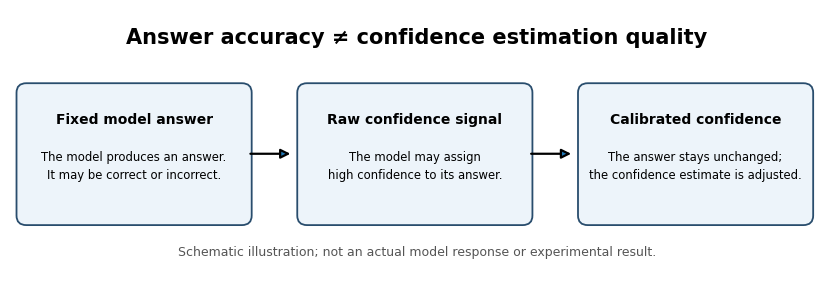

Saved: 01_problem_concept_en.png | 01_problem_concept_en.svg


In [5]:
fig,ax=plt.subplots(figsize=(10.5,3.5));ax.set_xlim(0,10);ax.set_ylim(0,3.4);ax.axis('off')
ax.text(5,3.05,'Answer accuracy ≠ confidence estimation quality',ha='center',va='center',fontsize=15,fontweight='bold')
items=[(0.2,'Fixed model answer','The model produces an answer.\nIt may be correct or incorrect.'),
       (3.65,'Raw confidence signal','The model may assign\nhigh confidence to its answer.'),
       (7.1,'Calibrated confidence','The answer stays unchanged;\nthe confidence estimate is adjusted.')]
for x,ttl,body in items:
    patch=FancyBboxPatch((x,.8),2.65,1.55,boxstyle='round,pad=0.12',linewidth=1.3,facecolor='#edf4fa',edgecolor='#294d6d')
    ax.add_patch(patch);ax.text(x+1.325,1.96,ttl,ha='center',fontweight='bold',fontsize=10)
    ax.text(x+1.325,1.43,body,ha='center',va='center',fontsize=8.4,linespacing=1.5)
for sx in [2.92,6.37]:ax.add_patch(FancyArrowPatch((sx,1.58),(sx+.56,1.58),arrowstyle='-|>',mutation_scale=14,lw=1.6))
ax.text(5,.3,'Schematic illustration; not an actual model response or experimental result.',ha='center',fontsize=9,color='#555555')
save(fig,'01_problem_concept_en','Difference between confidence estimation and answer accuracy. Conceptual diagram; no experimental data are shown.')

## 5 — Şekil 02: Tezin deneysel akışı (YÖNTEM ŞEMASI)

970 CLEAN_DEV soru/model ile öğrenilen kalibratörlerin 250 bağımsız test sorusunda değerlendirildiğini açık gösterir. **30 model seçimi sorusu CLEAN_DEV'e alınmadı; 50 reserve soru inference'a alınmadı.**

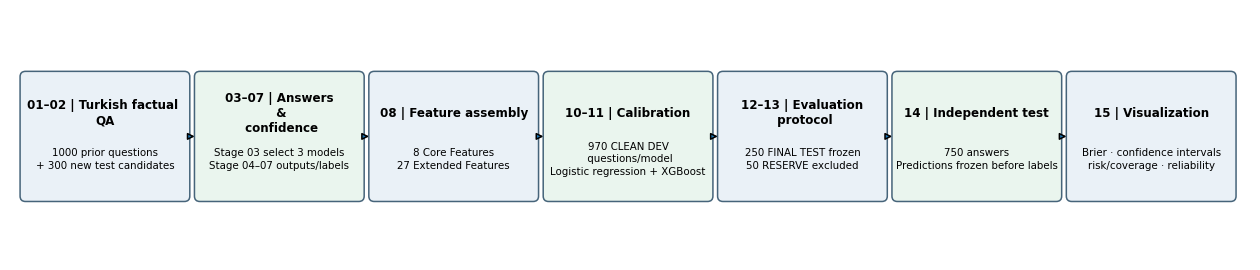

Saved: 02_experimental_workflow_en.png | 02_experimental_workflow_en.svg


In [6]:
fig,ax=plt.subplots(figsize=(16,3.25));ax.set_xlim(0,16);ax.set_ylim(0,3.25);ax.axis('off')
blocks=[('01–02 | Turkish factual \nQA','1000 prior questions\n+ 300 new test candidates'),
        ('03–07 | Answers\n &\n confidence','Stage 03 select 3 models\nStage 04–07 outputs/labels'),
        ('08 | Feature assembly','8 Core Features\n27 Extended Features'),
        ('10–11 | Calibration','970 CLEAN DEV\n questions/model\nLogistic regression + XGBoost'),
        ('12–13 | Evaluation\n protocol','250 FINAL TEST frozen\n50 RESERVE excluded'),
        ('14 | Independent test','750 answers\nPredictions frozen before labels'),
        ('15 | Visualization','Brier · confidence intervals\nrisk/coverage · reliability')]
box_w=2.05;box_h=1.55;gap=.20;x0=.20;y=.83
for i,(title,detail) in enumerate(blocks):
    x=x0+i*(box_w+gap)
    b=FancyBboxPatch((x,y),box_w,box_h,boxstyle='round,pad=0.07',linewidth=1.1,
                     facecolor=('#eaf1f7' if i not in (1,3,5) else '#eaf5ee'),edgecolor='#46647a')
    ax.add_patch(b)
    ax.text(x+box_w/2,y+1.08,title,fontsize=8.6,fontweight='bold',ha='center',va='center',wrap=True)
    ax.text(x+box_w/2,y+.48,detail,fontsize=7.4,ha='center',va='center',linespacing=1.35,wrap=True)
    if i<len(blocks)-1:
        ax.add_patch(FancyArrowPatch((x+box_w+.03,y+box_h/2),(x+box_w+gap-.03,y+box_h/2),
                                     arrowstyle='-|>',mutation_scale=10,lw=1.1))
#ax.set_title('Experimental workflow and data separation',fontsize=14,fontweight='bold',pad=0)
save(fig,'02_experimental_workflow_en','Workflow from data construction and CLEAN_DEV calibration to the independent 250-question final test.')

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12.5, 2.9))
ax.set_xlim(0, 12.5)
ax.set_ylim(0, 2.9)
ax.axis('off')

blocks = [
    ("01–02 | Dataset",
     "1000 validated questions\n+ 300 new candidates"),

    ("03–07 | Model outputs\nand labels",
     "3 models\nanswers, confidence,\nmanual correctness"),

    ("08–11 | Features and\ncalibration",
     "8 CORE features\nLogistic + XGBoost\n970 CLEAN-DEV/model"),

    ("12–13 | Frozen test\nprotocol",
     "250 FINAL TEST\n50 RESERVE\nfixed before inference"),

    ("14–15 | Final evaluation",
     "750 test answers\nBrier, bootstrap,\nselective prediction")
]

box_w = 2.15
box_h = 1.55
gap = 0.20
x0 = 0.15
y = 0.72

for i, (title, detail) in enumerate(blocks):
    x = x0 + i * (box_w + gap)

    face = '#eaf1f7' if i % 2 == 0 else '#eaf5ee'
    box = FancyBboxPatch(
        (x, y), box_w, box_h,
        boxstyle='round,pad=0.06',
        linewidth=1.0,
        facecolor=face,
        edgecolor='#46647a'
    )
    ax.add_patch(box)

    ax.text(
        x + box_w / 2, y + 1.05,
        title,
        fontsize=11.8,
        fontweight='bold',
        ha='center', va='center'
    )

    ax.text(
        x + box_w / 2, y + 0.48,
        detail,
        fontsize=10.5,
        ha='center', va='center',
        linespacing=1.25
    )

    if i < len(blocks) - 1:
        arrow = FancyArrowPatch(
            (x + box_w + 0.03, y + box_h / 2),
            (x + box_w + gap - 0.03, y + box_h / 2),
            arrowstyle='-|>',
            mutation_scale=10,
            lw=1.0,
            color='#46647a'
        )
        ax.add_patch(arrow)

fig.tight_layout(pad=0.2)

# PNG yerine PDF öneriyorum
fig.savefig("experimental_workflow.pdf", bbox_inches='tight')
fig.savefig("experimental_workflow.png", dpi=400, bbox_inches='tight')
plt.close(fig)

## 6 — Şekil 03: 250 final test sorusunda cevap doğruluğu

Buradaki **doğruluk oranı kalibrasyonla artmaz**; tek bir modelin dört yönteminde aynı cevaplar değerlendirilmiştir. Kaynak: Stage 14 `top_k`, coverage=1.0, 250 cevap/model.

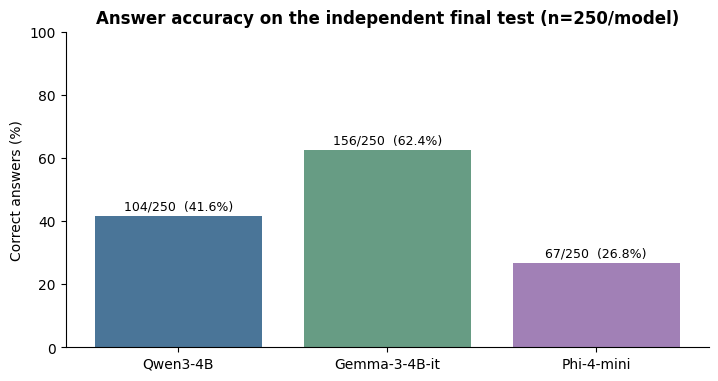

Saved: 03_final_test_accuracy.png | 03_final_test_accuracy.svg


In [10]:
full=sel.loc[(sel['policy']=='top_k') & np.isclose(sel['requested_coverage'],1.0) & (sel['method']=='logistic_core')].copy()
assert len(full)==3 and (full['n_selected']==250).all()
acc=(1-full.set_index('model_id').loc[models,'empirical_risk']).astype(float)
assert ((acc*250).round().astype(int)==pd.Series([104,156,67],index=models)).all()
fig,ax=plt.subplots(figsize=(8.3,4.1));bars=ax.bar([MODEL_NAME[m] for m in models],acc*100,color=['#4a7598','#679c84','#a180b6'])
ax.set_ylim(0,100);ax.set_ylabel('Correct answers (%)');ax.set_title('Answer accuracy on the independent final test (n=250/model)',fontweight='bold')
for b,m in zip(bars,models):ax.text(b.get_x()+b.get_width()/2,b.get_height()+2,f'{int(round(acc[m]*250))}/250  ({acc[m]*100:.1f}%)',ha='center',fontsize=9)
save(fig,'03_final_test_accuracy','Model answer accuracy on the independent test; post-hoc calibration does not change the answers.')

## 7 — Şekil 04: Brier skoru — ham sinyal, iki kalibratör ve sabit prevalans

**Düşük Brier daha iyi olasılık tahminini gösterir; modelin daha çok soruya doğru cevap verdiği anlamına gelmez.** Brier birincil ölçüttür.

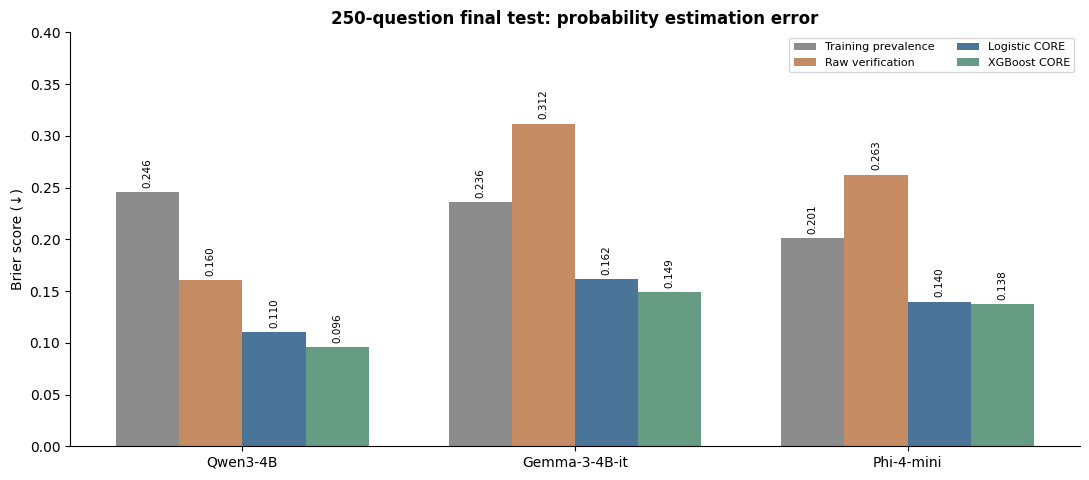

Saved: 04_brier_by_method.png | 04_brier_by_method.svg


In [11]:
order=['train_prevalence','raw_verification','logistic_core','xgb_core']
wide=met.pivot(index='model_id',columns='method',values='brier').loc[models,order]
fig,ax=plt.subplots(figsize=(11,4.9));x=np.arange(3);w=.19
colors=['#8c8c8c','#c58b62','#4a7598','#679c84']
for j,method in enumerate(order):
    vals=wide[method].to_numpy()
    bars=ax.bar(x+(j-1.5)*w,vals,width=w,label=METHOD_NAME[method],color=colors[j])
    for bar,val in zip(bars,vals):ax.text(bar.get_x()+bar.get_width()/2,val+.006,f'{val:.3f}',ha='center',fontsize=7.5,rotation=90)
ax.set_xticks(x,[MODEL_NAME[m] for m in models]);ax.set_ylim(0,max(.40,float(wide.max().max())+.08))
ax.set_ylabel('Brier score (↓)');ax.set_title('250-question final test: probability estimation error',fontweight='bold')
ax.legend(ncol=2,fontsize=8,loc='upper right');fig.tight_layout()
save(fig,'04_brier_by_method','Brier scores of raw and calibrated confidence probabilities on the final test (lower is better).')

## 8 — Şekil 05: XGBoost − lojistik Brier farkı ve %95 eşleştirilmiş bootstrap aralığı

Negatif değer, bu testte XGBoost Brier'ının daha düşük olduğunu gösterir. Aralığın sıfırı içermesi, farkın yönü konusunda belirsizlik bulunduğunu gösterir. 4000 bootstrap; **çoklu karşılaştırma düzeltmesi yoktur**.

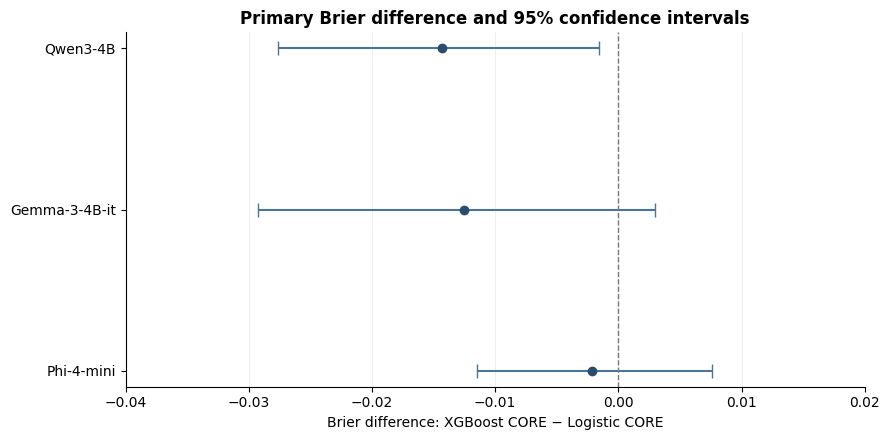

Saved: 05_brier_paired_difference_ci.png | 05_brier_paired_difference_ci.svg


In [12]:
bb=boot.loc[boot['comparison']=='brier_xgb_minus_logistic'].set_index('model_id').loc[models]
assert len(bb)==3 and (bb['n_independent_questions']==250).all() and (bb['n_bootstrap']==4000).all()
fig,ax=plt.subplots(figsize=(9,4.5));yy=np.arange(3)
effect=bb.effect.to_numpy();lo=bb.ci95_low.to_numpy();hi=bb.ci95_high.to_numpy()
ax.errorbar(effect,yy,xerr=np.vstack([effect-lo,hi-effect]),fmt='o',capsize=5,color='#294d6d',ecolor='#4a7598')
ax.axvline(0,color='#777777',linewidth=1,linestyle='--')
ax.set_yticks(yy,[MODEL_NAME[m] for m in models]);ax.invert_yaxis();ax.set_xlabel('Brier difference: XGBoost CORE − Logistic CORE')
ax.set_title('Primary Brier difference and 95% confidence intervals',fontweight='bold')
ax.set_xlim(min(-.04,float(lo.min())-.006),max(.02,float(hi.max())+.006));ax.grid(axis='x',alpha=.2)
fig.tight_layout();save(fig,'05_brier_paired_difference_ci','Paired Brier difference by model with 95% percentile bootstrap confidence intervals; 4000 resamples, unadjusted.')

In [13]:
bb = boot.loc[boot['comparison'] == 'brier_xgb_minus_logistic'].set_index('model_id').loc[models]
assert len(bb) == 3 and (bb['n_independent_questions'] == 250).all() and (bb['n_bootstrap'] == 4000).all()

display_names = {
    'Qwen/Qwen3-4B': 'Qwen3-4B',
    'google/gemma-3-4b-it': 'Gemma-3-4B-it',
    'microsoft/Phi-4-mini-instruct': 'Phi-4-mini'
}

fig, ax = plt.subplots(figsize=(6.6, 3.2))
yy = np.arange(3)

effect = bb['effect'].to_numpy()
lo = bb['ci95_low'].to_numpy()
hi = bb['ci95_high'].to_numpy()

ax.errorbar(
    effect,
    yy,
    xerr=np.vstack([effect - lo, hi - effect]),
    fmt='o',
    capsize=4,
    color='#294d6d',
    ecolor='#4a7598',
    elinewidth=1.2,
    markersize=5
)

ax.axvline(0, color='#777777', linewidth=1, linestyle='--')

ax.set_yticks(yy, [display_names[m] for m in models])
ax.invert_yaxis()

ax.set_xlabel('Brier difference (XGBoost − Logistic)', fontsize=9)
ax.tick_params(axis='both', labelsize=10.5)
ax.grid(axis='x', alpha=0.25)

xmin = min(-0.04, float(lo.min()) - 0.004)
xmax = max(0.02, float(hi.max()) + 0.004)
ax.set_xlim(xmin, xmax)

# Noktaların yanına effect değeri yaz
for x, y in zip(effect, yy):
    ax.text(x + 0.0012, y - 0.08, f'{x:.4f}', fontsize=8)

# Çerçeveyi sadeleştir
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout(pad=0.4)

fig.savefig("brier_difference_ci.pdf", bbox_inches='tight')
fig.savefig("brier_difference_ci.png", dpi=400, bbox_inches='tight')
plt.close(fig)

## 9 — Şekil 06: Coverage–risk ilişkisi (önceden belirlenen 4 coverage noktası)

Her model için ayrı grafik; çizgiler **yalnızca %20, %50, %80 ve %100 gözlenen noktaları** birleştirir, aradaki coverage seviyelerinde ek sonuç ölçülmüş gibi yorumlanmamalıdır. `top_k` yöntemi aynı sayıda cevabı seçer.

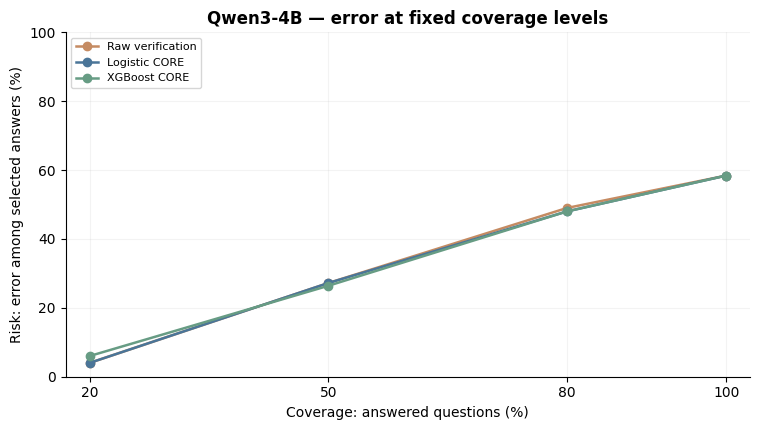

Saved: 06_risk_coverage_0.png | 06_risk_coverage_0.svg


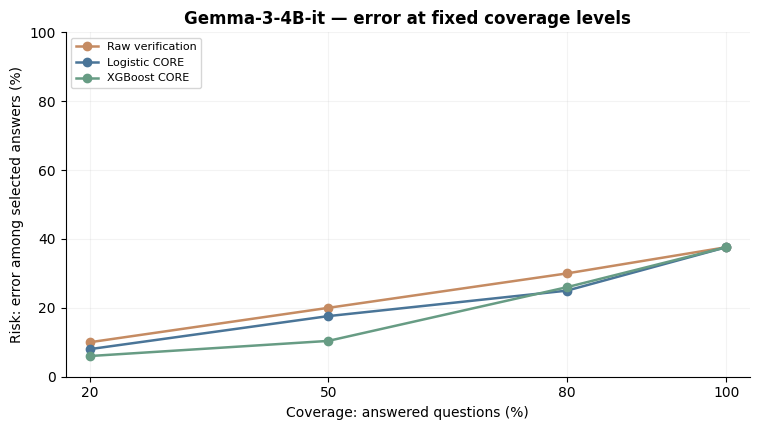

Saved: 06_risk_coverage_1.png | 06_risk_coverage_1.svg


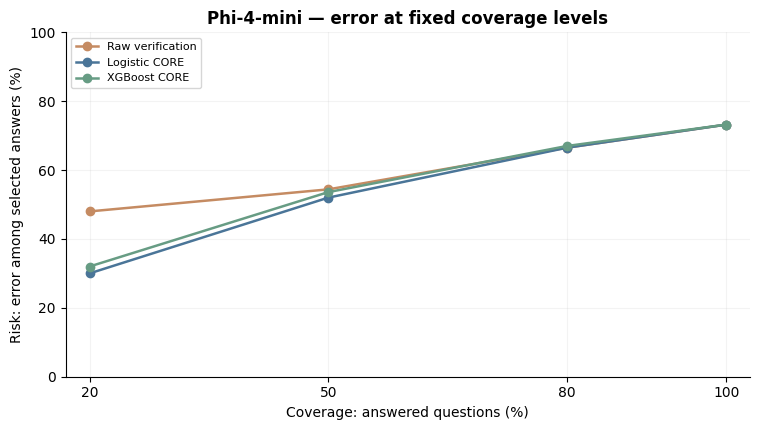

Saved: 06_risk_coverage_2.png | 06_risk_coverage_2.svg


In [20]:
levels=[.2,.5,.8,1.0]
for mid in models:
    fig,ax=plt.subplots(figsize=(7.7,4.4))
    for method,c in [('raw_verification','#c58b62'),('logistic_core','#4a7598'),('xgb_core','#679c84')]:
        df=sel.loc[(sel.model_id==mid)&(sel.method==method)&(sel.policy=='top_k')].sort_values('requested_coverage')
        assert len(df)==4 and np.allclose(df.requested_coverage.to_numpy(),levels)
        ax.plot(df.attained_coverage*100,df.empirical_risk*100,marker='o',label=METHOD_NAME[method],color=c,linewidth=1.8)
    ax.set_xticks([20,50,80,100]);ax.set_xlim(17,103);ax.set_ylim(bottom=0,top=100)
    ax.set_xlabel('Coverage: answered questions (%)');ax.set_ylabel('Risk: error among selected answers (%)')
    ax.set_title(MODEL_NAME[mid]+' — error at fixed coverage levels',fontweight='bold')
    ax.legend(loc='upper left',fontsize=8);ax.grid(alpha=.15);fig.tight_layout()
    name='06_risk_coverage_'+models.index(mid).__str__()
    save(fig,name,'Error rate for '+MODEL_NAME[mid]+' at four prespecified coverage levels on the 250-question final test.')

## 10 — Şekil 07: Güvenilirlik diyagramları (reliability diagrams)

**Yalnız bu hücre final test etiketlerini doğrudan görselleştirme amacıyla okur.** Tahminler Stage 14'te dondurulmuş dosyadan alınır; yeni kalibratör eğitimi veya yeni eşik seçimi yoktur. 10 eşit genişlikli güven aralığında ortalama tahmin edilen olasılık ile gözlenen doğruluğu karşılaştırır. Az sayıda gözlem içeren binlerin oranları oynaktır; veri olmayan bin çizilmez. `train_prevalence` bu şekle alınmamıştır çünkü sabit olasılık verir.

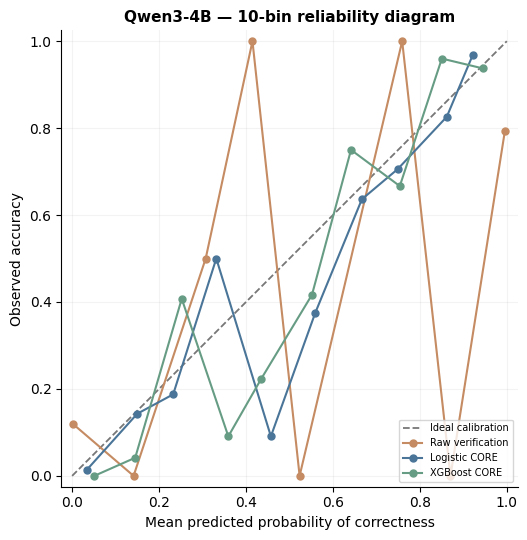

Saved: 07_reliability_0.png | 07_reliability_0.svg


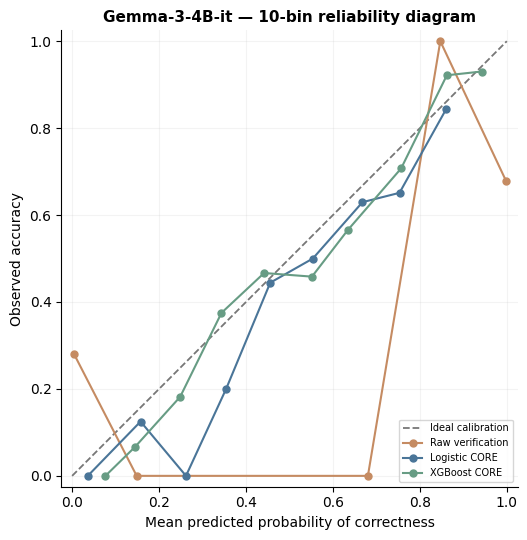

Saved: 07_reliability_1.png | 07_reliability_1.svg


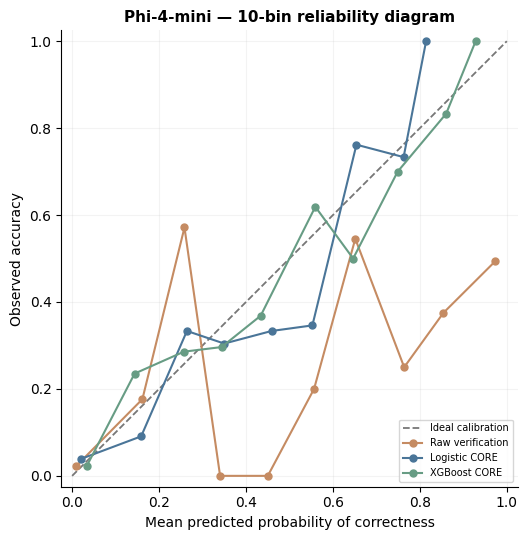

Saved: 07_reliability_2.png | 07_reliability_2.svg


In [21]:
pm=readj(PRED_MAN)
assert pm['predictions_sha256']==sha(PRED)
pr=pd.read_parquet(PRED,columns=['question_id','model_id','method','p_correct'])
yf=pd.read_parquet(CORE,columns=['question_id','model_id','manual_is_correct'])
yf=yf.loc[yf.question_id.isin(final_ids)].copy()
assert len(yf)==750 and len(pr)==3000
assert not yf.duplicated(['question_id','model_id']).any()
assert not pr.duplicated(['question_id','model_id','method']).any()
assert set(pr.question_id)==set(yf.question_id)==final_ids
assert set(pr.method)==set(METHOD_NAME)
joined=pr.merge(yf,on=['question_id','model_id'],validate='many_to_one',how='left')
assert len(joined)==3000 and joined.manual_is_correct.notna().all()
assert joined.manual_is_correct.isin([0,1]).all() and joined.p_correct.between(0,1).all()
for mid in models:
    fig,ax=plt.subplots(figsize=(6.3,5.5));ax.plot([0,1],[0,1],color='#777777',linestyle='--',linewidth=1.3,label='Ideal calibration')
    for method,c in [('raw_verification','#c58b62'),('logistic_core','#4a7598'),('xgb_core','#679c84')]:
        d=joined.loc[(joined.model_id==mid)&(joined.method==method)].copy()
        assert len(d)==250
        bins=np.minimum((d.p_correct.to_numpy()*10).astype(int),9)
        xx=[];yy=[];sizes=[]
        for k in range(10):
            mask=bins==k
            if mask.any():
                xx.append(float(d.p_correct.to_numpy()[mask].mean()))
                yy.append(float(d.manual_is_correct.to_numpy()[mask].mean()))
                sizes.append(int(mask.sum()))
        ax.plot(xx,yy,'o-',label=METHOD_NAME[method],color=c,markersize=5)
    ax.set_xlim(-.025,1.025);ax.set_ylim(-.025,1.025)
    ax.set_aspect('equal',adjustable='box');ax.set_xlabel('Mean predicted probability of correctness')
    ax.set_ylabel('Observed accuracy')
    ax.set_title(MODEL_NAME[mid]+' — 10-bin reliability diagram',fontweight='bold',fontsize=11)
    ax.legend(loc='lower right',fontsize=7);ax.grid(alpha=.15);fig.tight_layout()
    save(fig,'07_reliability_'+str(models.index(mid)),'Predicted confidence and observed accuracy for '+MODEL_NAME[mid]+' in 10 equal-width bins on the final test (n=250).')

## 11 — Şekil 08: Güven eşiği ile verilen cevap sayısı

0,80 ve 0,90 eşiğinde **seçilen cevap sayısı değişir**. Eşik bazlı hata oranlarını karşılaştırırken coverage ve n mutlaka belirtilmelidir; sıfır seçilen cevap için risk **tanımsızdır, %0 değildir**.

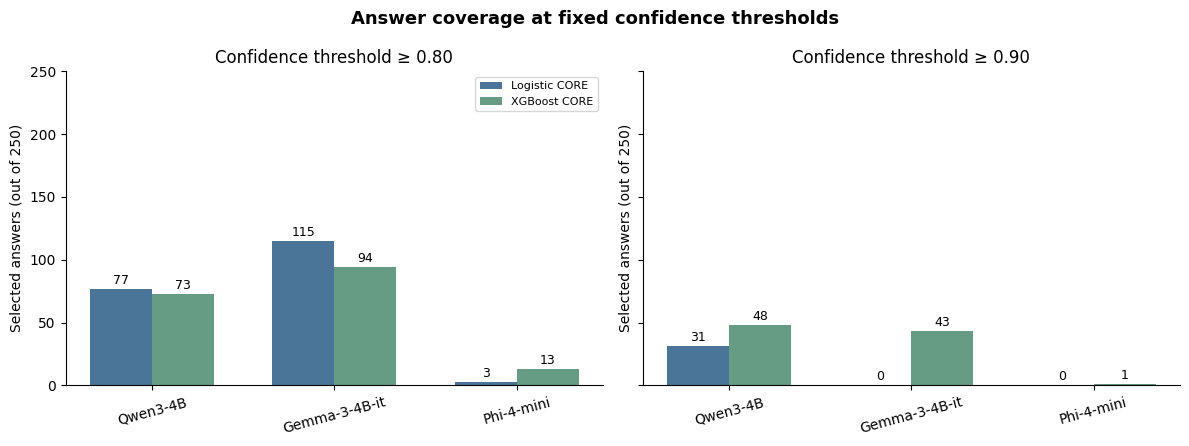

Saved: 08_threshold_selected_counts.png | 08_threshold_selected_counts.svg


In [22]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5),sharey=True)
for ax,t in zip(axes,[.8,.9]):
    x=np.arange(3);w=.34
    for j,(method,color) in enumerate([('logistic_core','#4a7598'),('xgb_core','#679c84')]):
        df=sel.loc[(sel.policy=='fixed_threshold')&(sel.method==method)&np.isclose(sel.threshold,t)].set_index('model_id').loc[models]
        bars=ax.bar(x+(-w/2 if j==0 else w/2),df.n_selected.to_numpy(),width=w,color=color,label=METHOD_NAME[method])
        for b,v in zip(bars,df.n_selected):ax.text(b.get_x()+b.get_width()/2,b.get_height()+4,str(int(v)),ha='center',fontsize=9)
    ax.set_xticks(x,[MODEL_NAME[m] for m in models],rotation=15)
    ax.set_title(f'Confidence threshold ≥ {t:.2f}');ax.set_ylim(0,250);ax.set_ylabel('Selected answers (out of 250)')
axes[0].legend(fontsize=8);fig.suptitle('Answer coverage at fixed confidence thresholds',fontweight='bold',fontsize=13)
fig.tight_layout();save(fig,'08_threshold_selected_counts','Number of selected answers at confidence thresholds of 0.80 and 0.90; risk is undefined when no answers are selected.')

## 12 — Şekil 09: Final testin zorluk dağılımı ve protokol sapması

Bu görsel **sınırlılıklar** bölümünde kullanılmalı. Başlangıçta planlanan easy=75 / medium=125 / hard=50 zorluk kotaları seçime uygulanmadı; seçilen sette 8 / 209 / 33 bulunuyor. Bu sapma model cevaplarına bakılmadan ayrı amendment dosyasında kaydedildi. **8 easy sorudan genelleme yapmayın.**

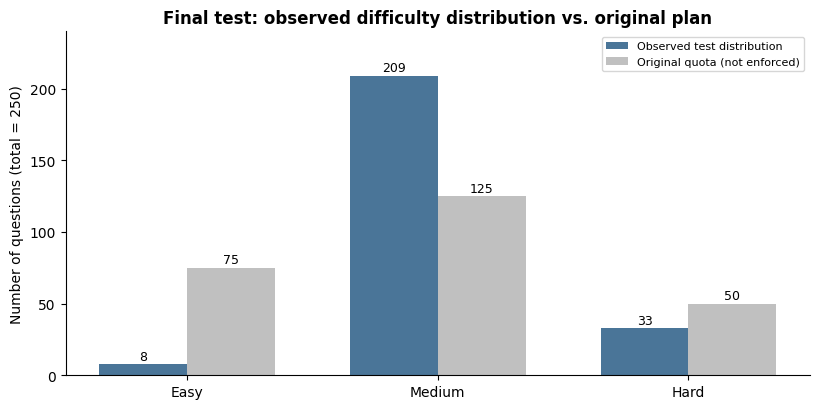

Saved: 09_difficulty_distribution.png | 09_difficulty_distribution.svg


In [23]:
levels=['easy','medium','hard'];counts=[diff[k] for k in levels];targets=[75,125,50]
fig,ax=plt.subplots(figsize=(8.3,4.2));x=np.arange(3);w=.35
left=ax.bar(x-w/2,counts,width=w,label='Observed test distribution',color='#4a7598')
right=ax.bar(x+w/2,targets,width=w,label='Original quota (not enforced)',color='#b1b1b1',alpha=.8)
for bars in [left,right]:
    for b in bars:ax.text(b.get_x()+b.get_width()/2,b.get_height()+3,str(int(b.get_height())),ha='center',fontsize=9)
ax.set_xticks(x,['Easy','Medium','Hard']);ax.set_ylim(0,240);ax.set_ylabel('Number of questions (total = 250)')
ax.set_title('Final test: observed difficulty distribution vs. original plan',fontweight='bold')
ax.legend(fontsize=8);fig.tight_layout();save(fig,'09_difficulty_distribution','Difficulty distribution of the 250-question final test; the planned difficulty quota was removed with documented justification before inference.')

## 13 — Şekil kataloğu, kaynak SHA dosyası ve kullanım notları

`figure_catalog_v1.csv`: Her görsel için ayrı, doğrudan kullanılabilir Türkçe şekil altyazısı. `stage15_visualization_manifest_v1.json`: Her girdi/çıktı SHA'sı ve bu stage'in salt-okunur olduğunun kaydı. PNG'yi Word/Google Docs'a, SVG'yi vektör biçiminde destekleyen editöre ekleyebilirsiniz.

**Önerilen 4–5 sayfalık giriş örgüsü:** (1) Olgusal QA ve hata sorunu; (2) doğruluk–güven ayrımı + Şekil 01; (3) araştırma sorusu, Brier ve post-hoc kalibrasyon kavramı; (4) Türkçe kapsam ve neden bağımsız test gerekli; (5) bu tezdeki veri/deney akışının kısa özeti + Şekil 02. Stage 14 metrik grafikleri giriş yerine bulgular bölümünde ayrıntılandırılmalıdır.

**Metodolojik sınır:** Şematik figürlerdeki kutular gerçek model örnekleri değildir. Brier grafikleri olasılık tahmin kalitesini, doğruluk grafiği modelin cevap doğruluğunu, coverage grafikleri cevabı yayımlamama politikasını gösterir. Bu üç kavramı aynı sonuç gibi yazmayın.

In [25]:
OUT.mkdir(parents=True,exist_ok=True)
catalog=pd.DataFrame(made)
assert len(catalog)==13,f'Beklenmeyen görsel sayısı: {len(catalog)}'
catalog_file=OUT/'figure_catalog_v1.csv'
catalog.to_csv(catalog_file,index=False,encoding='utf-8-sig')
source_files=list(EXPECTED)+[SPLIT,PRED_MAN,AMEND]
visualization_manifest={
    'stage':'15_thesis_explanation_and_visuals','version':'v1','dataset_version':VER,
    'read_only_input_artifacts':True,'no_training_no_inference_no_resampling':True,
    'final_test_question_count_per_model':250,'final_test_answer_count':750,
    'difficulty_counts_observed':dict(diff),
    'input_files_sha256':{str(p):sha(p) for p in source_files},
    'catalog_path':str(catalog_file),'catalog_sha256':sha(catalog_file),
    'figures':made,
    'limitations':['N=250/model, 3 models, fixed Turkish factual QA sample',
                   'Difficulty 8 easy, 209 medium, 33 hard; original quota not enforced',
                   'Reliability bin estimates uncertain with few observations',
                   'Bootstrap intervals descriptive, no multiplicity correction'],
}
mfile=OUT/'stage15_visualization_manifest_v1.json'
with mfile.open('w',encoding='utf-8') as f:
    json.dump(visualization_manifest,f,ensure_ascii=False,indent=2)
assert readj(mfile)['catalog_sha256']==sha(catalog_file)
print('STAGE 15 VISUALIZATION COMPLETE')
print('Generated figures:',len(made),'(PNG + SVG each)')
print('Figure catalog:',catalog_file)
print('Visualization manifest:',mfile,'SHA:',sha(mfile))
display(catalog[['figure','caption_en']])

AssertionError: Beklenmeyen görsel sayısı: 23